# PRCP-1020: House Price Prediction – Ames Housing Dataset


#### SETUP: Libraries and Data Loading

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, KFold, cross_val_score, cross_val_predict, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor        # pip install xgboost (if not installed)

sns.set_style("whitegrid")
pd.set_option("display.max_columns", 100)

### Load the Data

In [4]:
df = pd.read_csv(r'C:\Users\rupab\OneDrive\Desktop\House Price Prediction - Advanced\data.csv')      
print("Rows & Columns:",df.shape)
df.head()

Rows & Columns: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


#### TASK 1: Data Analysis Report
1.1 Basic overview

In [6]:
df.info()
df.describe().T
df.dtypes.value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

object     43
int64      35
float64     3
Name: count, dtype: int64

In [7]:
num_cols = df.select_dtypes(include=np.number).columns.drop(['Id','SalePrice']).to_list()
cat_cols = df.select_dtypes(include='object').columns.to_list()
print(f"Numerical: {len(num_cols)} | Categorical: {len(cat_cols)}")
print('Duplicate Rows:',df.duplicated().sum())

Numerical: 36 | Categorical: 43
Duplicate Rows: 0


1.2 Missing values

In [8]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)
pd.DataFrame({"Missing": missing, "Percent": missing_pct})

,Missing,Percent
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


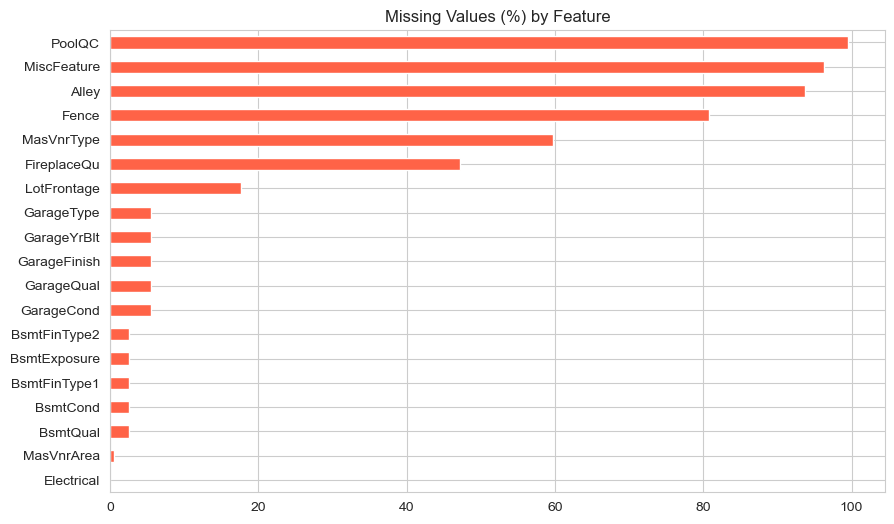

In [9]:
plt.figure(figsize=(10, 6))
missing_pct.plot(kind="barh", color="tomato")
plt.title("Missing Values (%) by Feature")
plt.gca().invert_yaxis()
plt.show()

Note: In this dataset, NA often means “feature not present”, not “data lost”. For example, PoolQC = NA means there is no pool

1.3 Target variable (SalePrice)

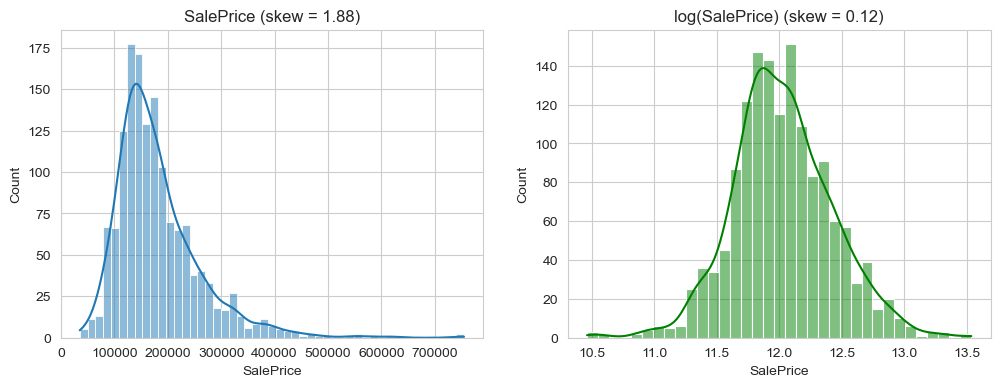

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["SalePrice"], kde=True, ax=ax[0])
ax[0].set_title(f"SalePrice (skew = {df['SalePrice'].skew():.2f})")
sns.histplot(np.log1p(df["SalePrice"]), kde=True, ax=ax[1], color="green")
ax[1].set_title(f"log(SalePrice) (skew = {np.log1p(df['SalePrice']).skew():.2f})")
plt.show()

SalePrice is right-skewed, so we will predict log(SalePrice) to make the distribution closer to normal and the models more stable.

1.4 Correlation with SalePrice

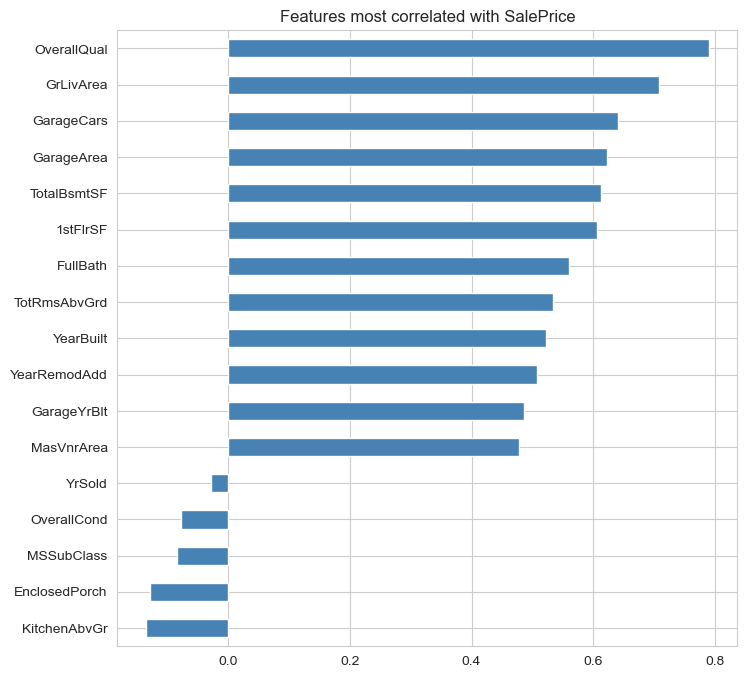

In [11]:
corr = df.select_dtypes(include=np.number).corr()["SalePrice"].drop("SalePrice").sort_values(ascending=False)

plt.figure(figsize=(8, 8))
pd.concat([corr.head(12), corr.tail(5)]).plot(kind="barh", color="steelblue")
plt.title("Features most correlated with SalePrice")
plt.gca().invert_yaxis()
plt.show()

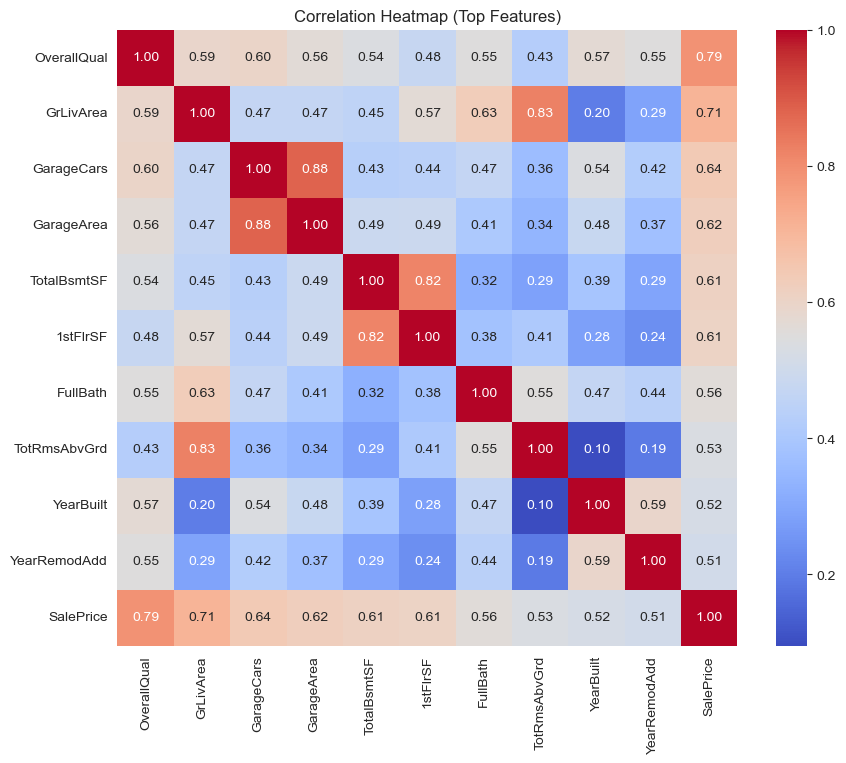

In [12]:
top_feats = corr.abs().sort_values(ascending=False).head(10).index.tolist() + ["SalePrice"]
plt.figure(figsize=(10, 8))
sns.heatmap(df[top_feats].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap (Top Features)")
plt.show()

1.5 Key relationships

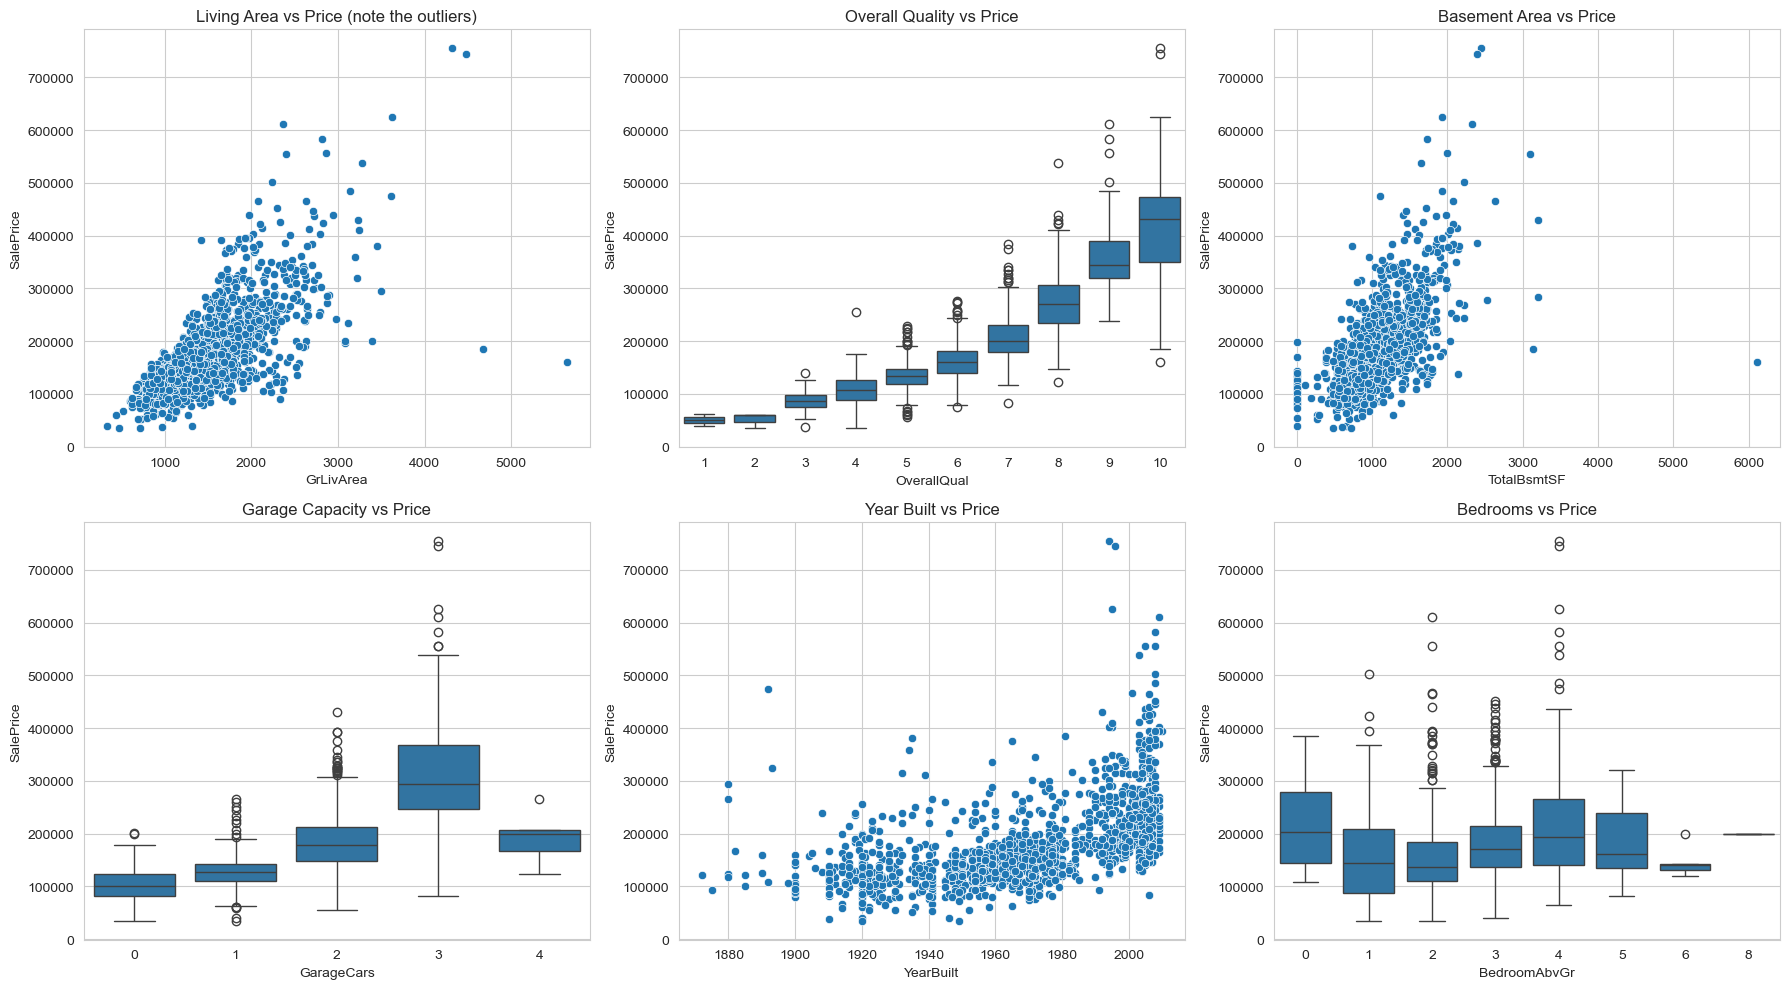

In [13]:
fig, ax = plt.subplots(2, 3, figsize=(18, 10))

sns.scatterplot(data=df, x="GrLivArea", y="SalePrice", ax=ax[0, 0])
ax[0, 0].set_title("Living Area vs Price (note the outliers)")

sns.boxplot(data=df, x="OverallQual", y="SalePrice", ax=ax[0, 1])
ax[0, 1].set_title("Overall Quality vs Price")

sns.scatterplot(data=df, x="TotalBsmtSF", y="SalePrice", ax=ax[0, 2])
ax[0, 2].set_title("Basement Area vs Price")

sns.boxplot(data=df, x="GarageCars", y="SalePrice", ax=ax[1, 0])
ax[1, 0].set_title("Garage Capacity vs Price")

sns.scatterplot(data=df, x="YearBuilt", y="SalePrice", ax=ax[1, 1])
ax[1, 1].set_title("Year Built vs Price")

sns.boxplot(data=df, x="BedroomAbvGr", y="SalePrice", ax=ax[1, 2])
ax[1, 2].set_title("Bedrooms vs Price")

plt.tight_layout()
plt.show()

IQR bounds: $3,938 to $340,038
Outliers by IQR: 61 houses (4.2%)


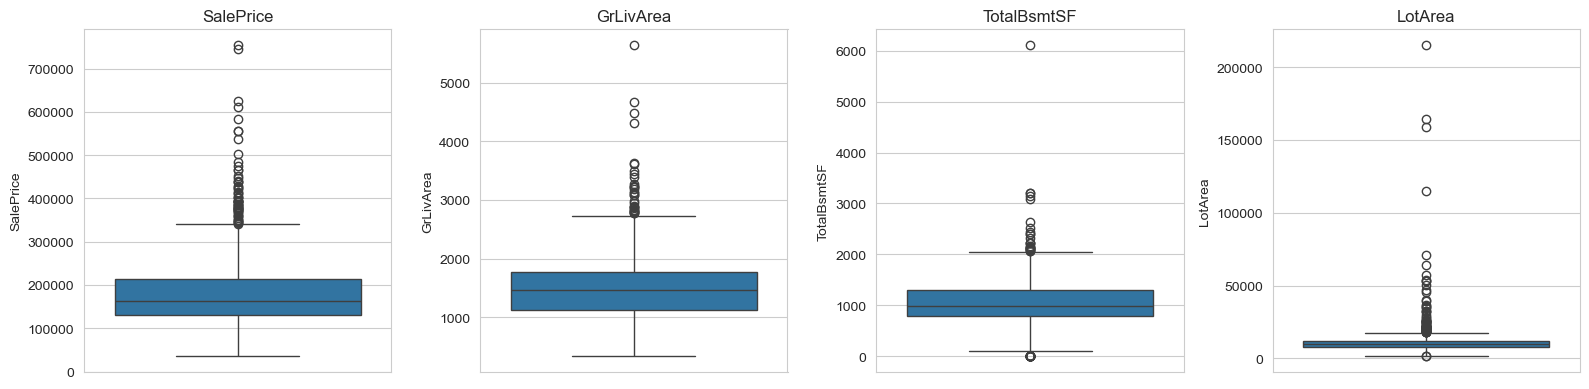

In [14]:
# IQR method on SalePrice
Q1, Q3 = df["SalePrice"].quantile([0.25, 0.75])
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
iqr_outliers = df[(df["SalePrice"] < lower) | (df["SalePrice"] > upper)]
print(f"IQR bounds: ${lower:,.0f} to ${upper:,.0f}")
print(f"Outliers by IQR: {len(iqr_outliers)} houses ({len(iqr_outliers)/len(df)*100:.1f}%)")

# Boxplots for the main numeric features
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for a, c in zip(ax, ["SalePrice", "GrLivArea", "TotalBsmtSF", "LotArea"]):
    sns.boxplot(y=df[c], ax=a)
    a.set_title(c)
plt.tight_layout()
plt.show()

1.6 Neighborhood analysis

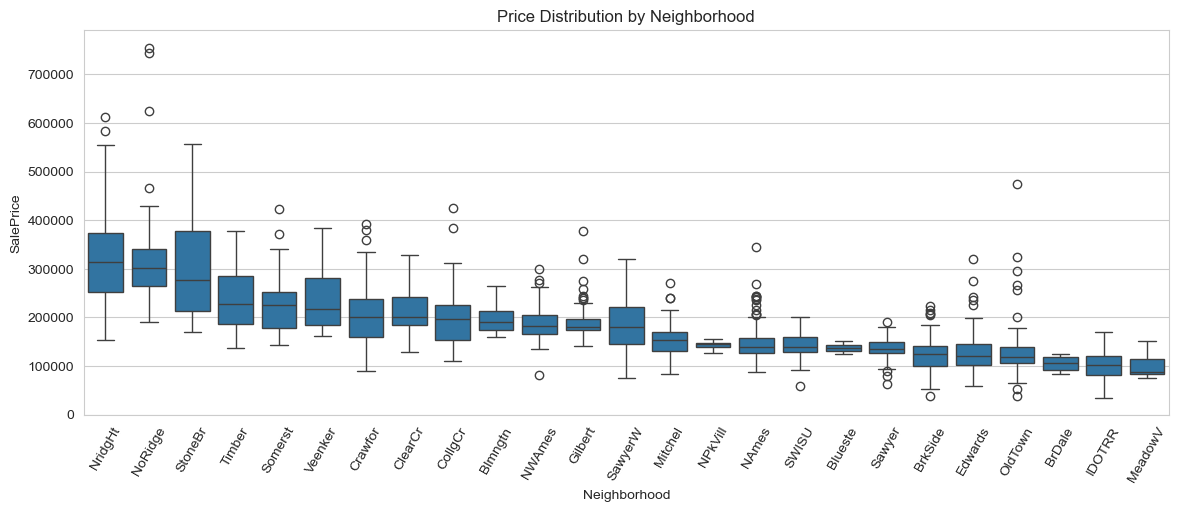

,count,median,mean
Neighborhood,,,
NridgHt,77,315000.0,316271.0
NoRidge,41,301500.0,335295.0
StoneBr,25,278000.0,310499.0
Timber,38,228475.0,242247.0
Somerst,86,225500.0,225380.0
Veenker,11,218000.0,238773.0
Crawfor,51,200624.0,210625.0
ClearCr,28,200250.0,212565.0
CollgCr,150,197200.0,197966.0


In [15]:
order = df.groupby("Neighborhood")["SalePrice"].median().sort_values(ascending=False).index

plt.figure(figsize=(14, 5))
sns.boxplot(data=df, x="Neighborhood", y="SalePrice", order=order)
plt.xticks(rotation=60)
plt.title("Price Distribution by Neighborhood")
plt.show()

df.groupby("Neighborhood")["SalePrice"].agg(["count", "median", "mean"]).sort_values("median", ascending=False).round(0)

1.7 Time trends

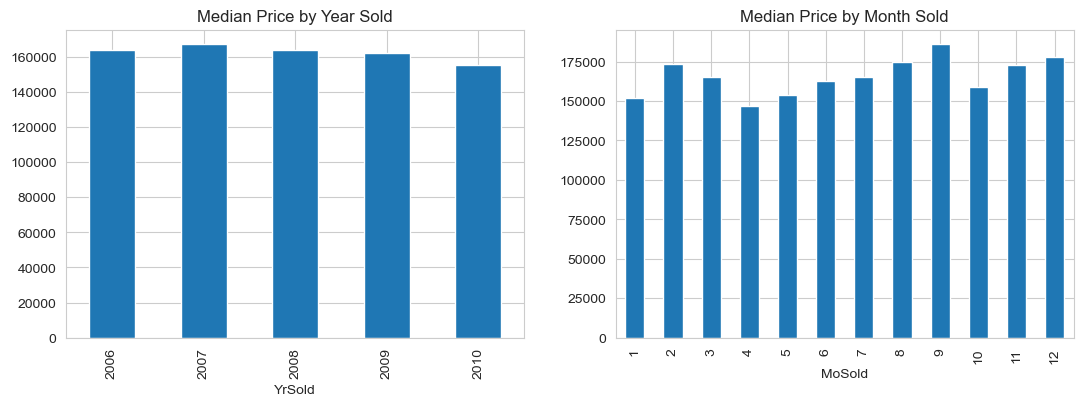

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
df.groupby("YrSold")["SalePrice"].median().plot(kind="bar", ax=ax[0], title="Median Price by Year Sold")
df.groupby("MoSold")["SalePrice"].median().plot(kind="bar", ax=ax[1], title="Median Price by Month Sold")
plt.show()

**Task 1 conclusion:** SalePrice is right-skewed, so the log transform is used for modelling. Most missing values mean the feature does not exist (no pool, no garage, no basement), so they are filled with "None" or 0; only LotFrontage and Electrical are truly missing. Overall quality and living area are among the strongest drivers of price, location (Neighborhood) matters a lot, and two partial-sale outliers (GrLivArea > 4000, low price) were removed.

#### Data Cleaning & Feature Engineering

2.1 Remove outliers

In [17]:
print("Before:", df.shape)
df = df[~((df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000))].reset_index(drop=True)
print("After :", df.shape)

Before: (1460, 81)
After : (1458, 81)



 2.2 Handle missing values

In [19]:
# Columns where NaN means "feature does not exist"
none_cols = ["Alley", "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
             "FireplaceQu", "GarageType", "GarageFinish", "GarageQual", "GarageCond",
             "PoolQC", "Fence", "MiscFeature", "MasVnrType"]
for c in none_cols:
    df[c] = df[c].fillna("None")

# Numeric columns where NaN means 0
for c in ["GarageYrBlt", "MasVnrArea"]:
    df[c] = df[c].fillna(0)

# LotFrontage: median of the same neighborhood
df["LotFrontage"] = df.groupby("Neighborhood")["LotFrontage"].transform(lambda x: x.fillna(x.median()))
df["LotFrontage"] = df["LotFrontage"].fillna(df["LotFrontage"].median())

# Electrical: 1 missing row, fill with the most frequent value
df["Electrical"] = df["Electrical"].fillna(df["Electrical"].mode()[0])

print("Remaining missing values:", df.isnull().sum().sum())   # 0

Remaining missing values: 0


2.3 Encode quality ratings (ordinal)

In [20]:
quality_map = {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
quality_cols = ["ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC",
                "KitchenQual", "FireplaceQu", "GarageQual", "GarageCond", "PoolQC"]
for c in quality_cols:
    df[c] = df[c].map(quality_map).fillna(0)

df["BsmtExposure"] = df["BsmtExposure"].map({"None": 0, "No": 1, "Mn": 2, "Av": 3, "Gd": 4})
df["GarageFinish"] = df["GarageFinish"].map({"None": 0, "Unf": 1, "RFn": 2, "Fin": 3})

2.4 Feature engineering

In [21]:
df["TotalSF"]       = df["TotalBsmtSF"] + df["1stFlrSF"] + df["2ndFlrSF"]
df["TotalBath"]     = df["FullBath"] + 0.5 * df["HalfBath"] + df["BsmtFullBath"] + 0.5 * df["BsmtHalfBath"]
df["TotalPorchSF"]  = df["OpenPorchSF"] + df["EnclosedPorch"] + df["3SsnPorch"] + df["ScreenPorch"] + df["WoodDeckSF"]
df["HouseAge"]      = df["YrSold"] - df["YearBuilt"]
df["RemodAge"]      = df["YrSold"] - df["YearRemodAdd"]
df["IsRemodeled"]   = (df["YearBuilt"] != df["YearRemodAdd"]).astype(int)
df["HasPool"]       = (df["PoolArea"] > 0).astype(int)
df["HasGarage"]     = (df["GarageArea"] > 0).astype(int)
df["HasBasement"]   = (df["TotalBsmtSF"] > 0).astype(int)
df["Has2ndFloor"]   = (df["2ndFlrSF"] > 0).astype(int)
df["HasFireplace"]  = (df["Fireplaces"] > 0).astype(int)
df["QualXArea"]     = df["OverallQual"] * df["GrLivArea"]   # interaction feature

# Year-sold and MSSubClass are really categories, not quantities
df["MSSubClass"] = df["MSSubClass"].astype(str)
df["MoSold"]     = df["MoSold"].astype(str)

2.5 Split data and build preprocessing pipeline

In [22]:
X = df.drop(columns=["Id", "SalePrice"])
y = np.log1p(df["SalePrice"])          # log-transformed target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

num_features = X.select_dtypes(include=np.number).columns.tolist()
cat_features = X.select_dtypes(include="object").columns.tolist()

preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler())]), num_features),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_features),
])

print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print(f"Numeric: {len(num_features)} | Categorical: {len(cat_features)}")

Train: (1166, 91) | Test: (292, 91)
Numeric: 58 | Categorical: 33


#### TASK 2a: Machine Learning Models
3.1 Compare multiple models

In [23]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge":             Ridge(alpha=10),
    "Lasso":             Lasso(alpha=0.001),
    "ElasticNet":        ElasticNet(alpha=0.001, l1_ratio=0.5),
    "Random Forest":     RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=500, learning_rate=0.05,
                                                   max_depth=3, subsample=0.8, random_state=42),
    "XGBoost":           XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=3,
                                      subsample=0.8, colsample_bytree=0.8, random_state=42),
}

def to_price(log_pred):
    """Convert log-price to dollars safely (avoids overflow to infinity)."""
    return np.expm1(np.clip(log_pred, 0, 20))

kf = KFold(n_splits=5, shuffle=True, random_state=42)
results = []

for name, model in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])

    # 5-fold cross validation on training data (RMSE on log scale)
    cv_rmse = -cross_val_score(pipe, X_train, y_train, cv=kf,
                               scoring="neg_root_mean_squared_error", n_jobs=-1)

    # Fit and evaluate on the unseen test set
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)

    results.append({
        "Model": name,
        "CV RMSE (log)": cv_rmse.mean(),
        "CV Std": cv_rmse.std(),
        "Test RMSE (log)": np.sqrt(mean_squared_error(y_test, pred)),
        "Test R2": r2_score(y_test, pred),
        "Test MAE ($)": mean_absolute_error(to_price(y_test), to_price(pred)),
    })

results_df = pd.DataFrame(results).sort_values("CV RMSE (log)").reset_index(drop=True)
results_df.round(4)

,Model,CV RMSE (log),CV Std,Test RMSE (log),Test R2,Test MAE ($)
0,XGBoost,1.125000e-01,1.140000e-02,1.138000e-01,9.232000e-01,1.321113e+04
1,ElasticNet,1.129000e-01,1.050000e-02,1.168000e-01,9.190000e-01,1.404562e+04
2,Ridge,1.132000e-01,1.110000e-02,1.228000e-01,9.105000e-01,1.443629e+04
3,Gradient Boosting,1.133000e-01,1.180000e-02,1.163000e-01,9.198000e-01,1.368908e+04
4,Lasso,1.139000e-01,9.400000e-03,1.178000e-01,9.176000e-01,1.391585e+04
5,Random Forest,1.321000e-01,1.080000e-02,1.401000e-01,8.836000e-01,1.587718e+04
6,Linear Regression,1.074807e+10,9.589979e+09,2.651202e+08,-4.169549e+17,3.337050e+06


3.2 Visualise comparison

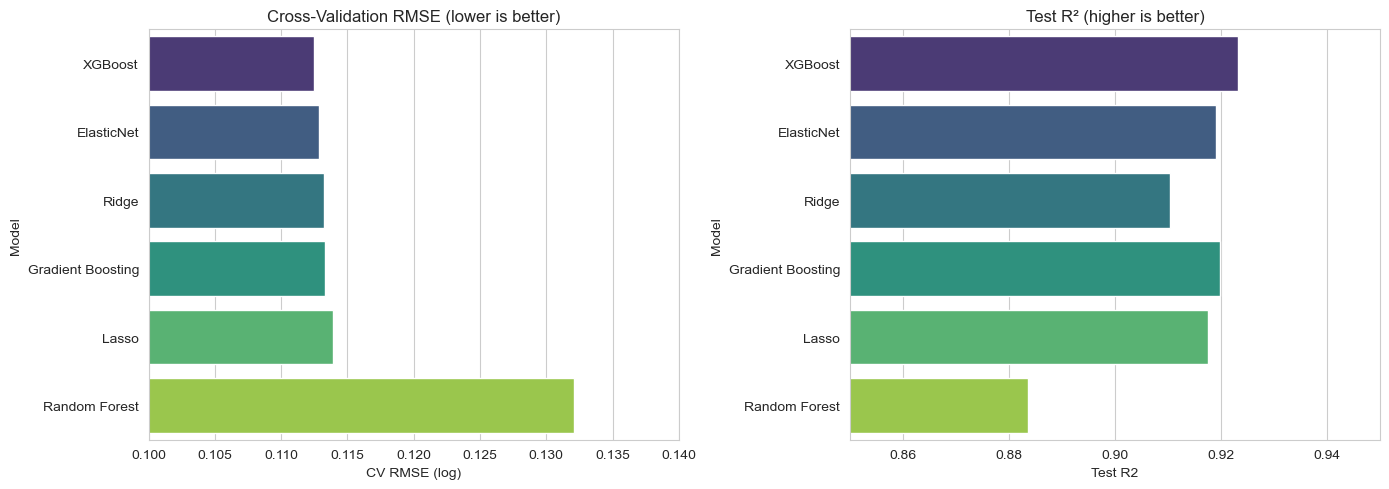

In [24]:
plot_df = results_df[results_df["Model"] != "Linear Regression"]

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=plot_df, y="Model", x="CV RMSE (log)", ax=ax[0], palette="viridis")
ax[0].set_title("Cross-Validation RMSE (lower is better)")
ax[0].set_xlim(0.10, 0.14)

sns.barplot(data=plot_df, y="Model", x="Test R2", ax=ax[1], palette="viridis")
ax[1].set_title("Test R² (higher is better)")
ax[1].set_xlim(0.85, 0.95)

plt.tight_layout()
plt.show()

3.3 Hyperparameter tuning of the best tree model

In [25]:
gb_pipe = Pipeline([("prep", preprocessor),
                    ("model", GradientBoostingRegressor(random_state=42))])

param_grid = {
    "model__n_estimators":     [300, 500, 800],
    "model__learning_rate":    [0.01, 0.03, 0.05],
    "model__max_depth":        [2, 3, 4],
    "model__subsample":        [0.7, 0.8, 1.0],
    "model__min_samples_leaf": [3, 5, 10],
}

search = RandomizedSearchCV(gb_pipe, param_grid, n_iter=15, cv=5,
                            scoring="neg_root_mean_squared_error",
                            random_state=42, n_jobs=-1, verbose=1)
search.fit(X_train, y_train)

print("Best params:", search.best_params_)
print("Best CV RMSE:", -search.best_score_)

Fitting 5 folds for each of 15 candidates, totalling 75 fits
Best params: {'model__subsample': 0.8, 'model__n_estimators': 500, 'model__min_samples_leaf': 5, 'model__max_depth': 2, 'model__learning_rate': 0.05}
Best CV RMSE: 0.117766408888487


3.4 Final model evaluation

In [26]:
best_model = search.best_estimator_
pred_log = best_model.predict(X_test)

pred_price = np.expm1(pred_log)
true_price = np.expm1(y_test)

print(f"R2 Score : {r2_score(y_test, pred_log):.4f}")
print(f"RMSE ($) : {np.sqrt(mean_squared_error(true_price, pred_price)):,.0f}")
print(f"MAE  ($) : {mean_absolute_error(true_price, pred_price):,.0f}")
print(f"MAPE     : {np.mean(np.abs(true_price - pred_price) / true_price) * 100:.2f}%")

R2 Score : 0.9226
RMSE ($) : 19,533
MAE  ($) : 14,162
MAPE     : 8.45%


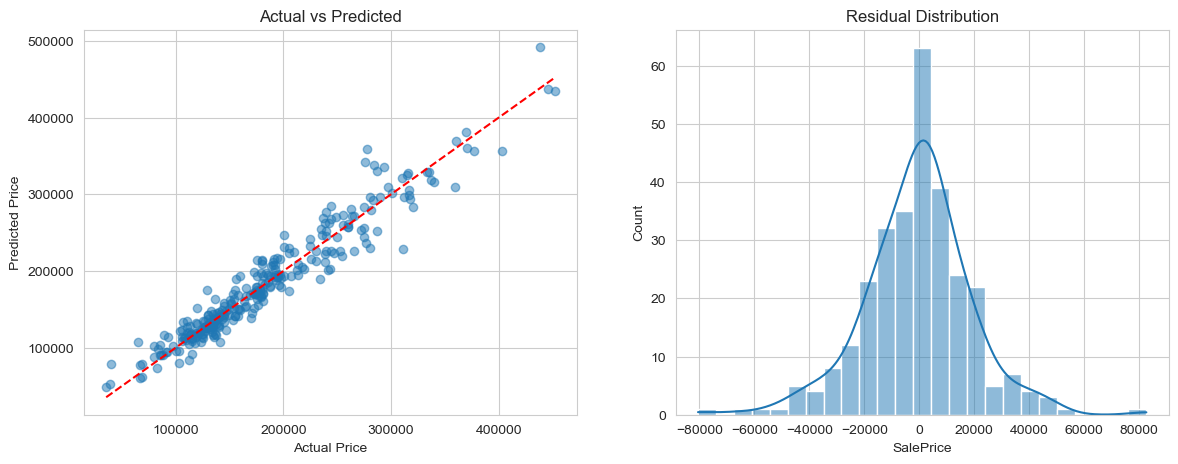

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].scatter(true_price, pred_price, alpha=0.5)
ax[0].plot([true_price.min(), true_price.max()], [true_price.min(), true_price.max()], "r--")
ax[0].set_xlabel("Actual Price"); ax[0].set_ylabel("Predicted Price")
ax[0].set_title("Actual vs Predicted")

residuals = true_price - pred_price
sns.histplot(residuals, kde=True, ax=ax[1])
ax[1].set_title("Residual Distribution")
plt.show()

#### TASK 2b: Feature Relationships
4.1 Feature importance

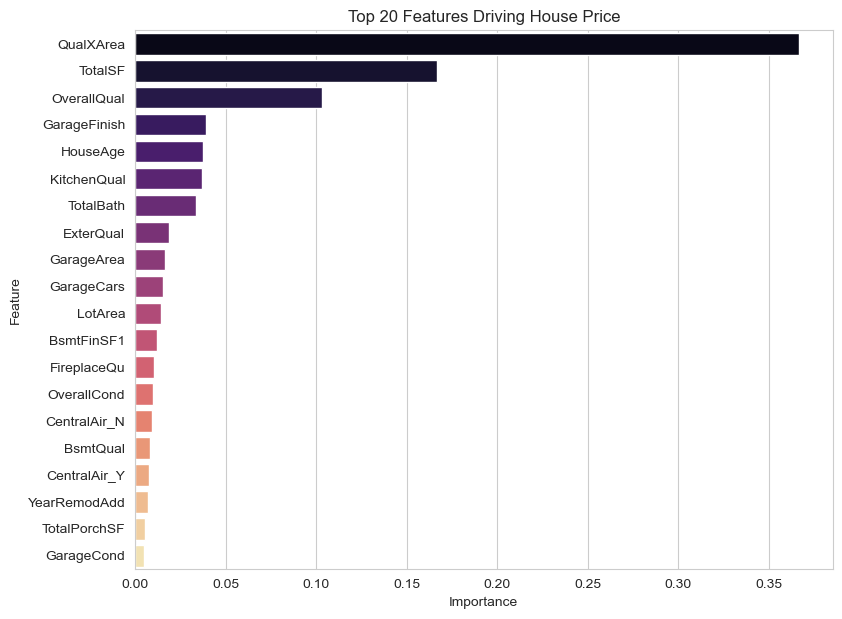

In [28]:
feature_names = best_model.named_steps["prep"].get_feature_names_out()
importances = best_model.named_steps["model"].feature_importances_

imp_df = (pd.DataFrame({"Feature": feature_names, "Importance": importances})
          .sort_values("Importance", ascending=False).head(20))
imp_df["Feature"] = imp_df["Feature"].str.replace("num__", "").str.replace("cat__", "")

plt.figure(figsize=(9, 7))
sns.barplot(data=imp_df, y="Feature", x="Importance", palette="magma")
plt.title("Top 20 Features Driving House Price")
plt.show()

4.2 How much does each feature change the price?

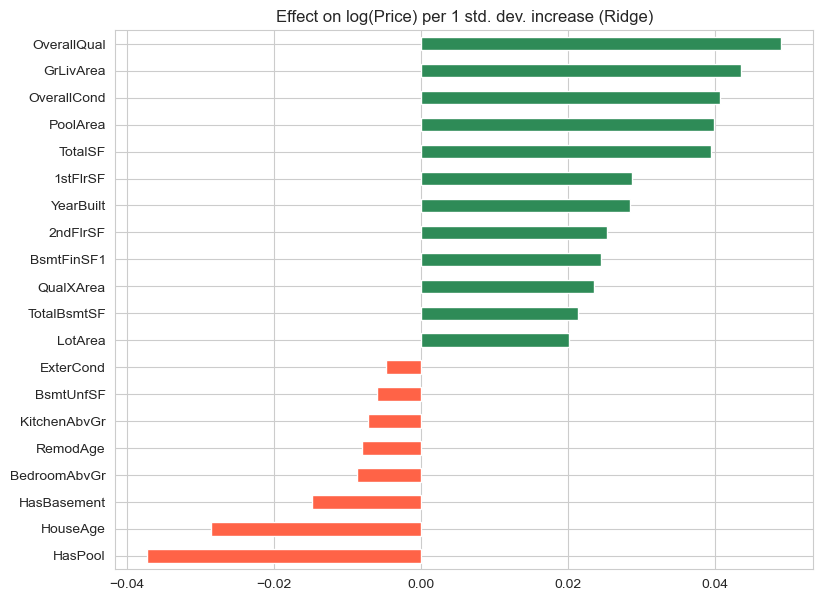

In [29]:
# Use Ridge coefficients on the log scale: coef * 100 is roughly % change in price per 1 std. dev.
ridge_pipe = Pipeline([("prep", preprocessor), ("model", Ridge(alpha=10))]).fit(X_train, y_train)
names = ridge_pipe.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(ridge_pipe.named_steps["model"].coef_, index=names)

num_coefs = coefs[coefs.index.str.startswith("num__")]
num_coefs.index = num_coefs.index.str.replace("num__", "")

top = pd.concat([num_coefs.sort_values().head(8), num_coefs.sort_values().tail(12)])
plt.figure(figsize=(9, 7))
top.plot(kind="barh", color=["tomato" if v < 0 else "seagreen" for v in top])
plt.title("Effect on log(Price) per 1 std. dev. increase (Ridge)")
plt.show()

4.3 Partial dependence (price vs a single feature)

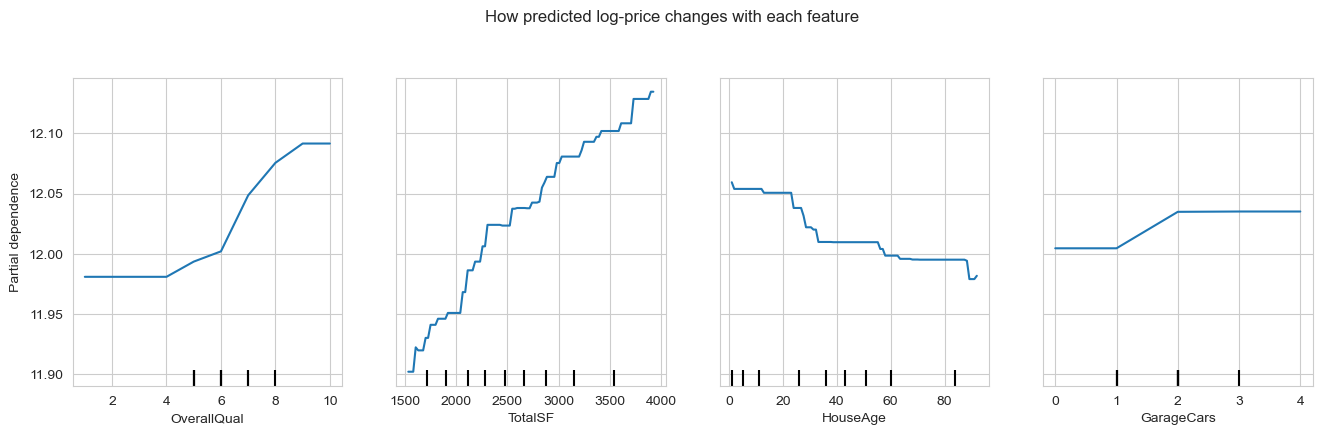

In [30]:
from sklearn.inspection import PartialDependenceDisplay

# Newer scikit-learn versions need float columns for partial dependence
X_pd = X_train.copy()
X_pd[num_features] = X_pd[num_features].astype(float)

PartialDependenceDisplay.from_estimator(
    best_model, X_pd, ["OverallQual", "TotalSF", "HouseAge", "GarageCars"], n_cols=4
)
plt.gcf().set_size_inches(16, 4)
plt.suptitle("How predicted log-price changes with each feature", y=1.05)
plt.show()

#### Simple “what-if” price calculator

In [31]:
sample = X_test.iloc[[0]].copy()
base = np.expm1(best_model.predict(sample))[0]
print(f"Base predicted price: ${base:,.0f}")

for q in [5, 6, 7, 8]:
    s = sample.copy()
    s["OverallQual"] = q
    s["QualXArea"] = q * s["GrLivArea"].values[0]
    print(f"OverallQual = {q}: ${np.expm1(best_model.predict(s))[0]:,.0f}")

Base predicted price: $211,082
OverallQual = 5: $189,225
OverallQual = 6: $198,461
OverallQual = 7: $211,082
OverallQual = 8: $235,212


#### TASK 3: Buying Suggestions for Customers
5.1 Build a market table with fair-value predictions

In [32]:
# Out-of-fold predictions: each house is predicted by a model that has NOT seen it
oof_log = cross_val_predict(best_model, X, y, cv=5, n_jobs=-1)

market = df.copy()
market["PredictedPrice"] = np.expm1(oof_log).round(0)
market["Savings"] = market["PredictedPrice"] - market["SalePrice"]        # +ve = undervalued
market["ValueScore%"] = (market["Savings"] / market["PredictedPrice"] * 100).round(1)

# Keep only normal sales: partial / abnormal / family sales look like fake bargains
market = market[market["SaleCondition"] == "Normal"].copy()
print("Houses in market table:", market.shape[0])

Houses in market table: 1198


5.2 Recommendation function

In [33]:
def recommend_houses(budget, min_area=0, min_bedrooms=0, min_bathrooms=0,
                     neighborhoods=None, min_quality=1, need_garage=False,
                     max_age=None, top_n=5):
    """Return the best-value houses matching the buyer's needs."""
    r = market[market["SalePrice"] <= budget]
    r = r[(r["GrLivArea"] >= min_area) &
          (r["BedroomAbvGr"] >= min_bedrooms) &
          (r["TotalBath"] >= min_bathrooms) &
          (r["OverallQual"] >= min_quality)]

    if neighborhoods:
        r = r[r["Neighborhood"].isin(neighborhoods)]
    if need_garage:
        r = r[r["GarageCars"] >= 1]
    if max_age is not None:
        r = r[r["HouseAge"] <= max_age]

    cols = ["Id", "Neighborhood", "SalePrice", "PredictedPrice", "ValueScore%",
            "GrLivArea", "BedroomAbvGr", "TotalBath", "OverallQual", "GarageCars", "HouseAge"]
    return r.sort_values("ValueScore%", ascending=False)[cols].head(top_n)

5.3 Example buyers

In [34]:
print("Family buyer: budget $250k, 3+ bedrooms, 1500+ sqft, garage")
display(recommend_houses(budget=250000, min_area=1500, min_bedrooms=3,
                         min_bathrooms=2, min_quality=6, need_garage=True))

print("Budget buyer: under $150k, 2+ bedrooms")
display(recommend_houses(budget=150000, min_bedrooms=2, min_quality=5))

print("Premium buyer: NridgHt / StoneBr, 7+ quality, newer houses")
display(recommend_houses(budget=450000, min_quality=7,
                         neighborhoods=["NridgHt", "StoneBr"], max_age=15))

Family buyer: budget $250k, 3+ bedrooms, 1500+ sqft, garage


,Id,Neighborhood,SalePrice,PredictedPrice,ValueScore%,GrLivArea,BedroomAbvGr,TotalBath,OverallQual,GarageCars,HouseAge
66,67,NAmes,180000,247836.0,27.4,2207,3,3.0,7,2,40
1210,1212,Gilbert,164000,223466.0,26.6,1752,4,2.0,8,2,22
1384,1387,NWAmes,250000,322305.0,22.4,2784,5,4.5,7,2,28
894,896,NAmes,140000,172749.0,19.0,1796,4,2.5,6,2,45
939,941,Mitchel,150900,184653.0,18.3,1728,4,2.0,6,2,30


Budget buyer: under $150k, 2+ bedrooms


,Id,Neighborhood,SalePrice,PredictedPrice,ValueScore%,GrLivArea,BedroomAbvGr,TotalBath,OverallQual,GarageCars,HouseAge
462,463,Sawyer,62383,124201.0,49.8,864,3,1.0,5,1,44
1061,1063,OldTown,90000,137827.0,34.7,2337,5,2.0,5,2,107
1381,1384,Sawyer,112000,156010.0,28.2,1416,3,2.0,5,2,89
713,715,Sawyer,130500,180956.0,27.9,1479,3,2.5,6,2,34
559,561,Sawyer,121500,161207.0,24.6,1392,3,2.5,5,2,53


Premium buyer: NridgHt / StoneBr, 7+ quality, newer houses


,Id,Neighborhood,SalePrice,PredictedPrice,ValueScore%,GrLivArea,BedroomAbvGr,TotalBath,OverallQual,GarageCars,HouseAge
1357,1360,NridgHt,315000,375806.0,16.2,1980,3,3.0,9,3,2
743,745,StoneBr,180000,214150.0,15.9,1337,2,3.0,8,2,15
348,349,NridgHt,154000,180817.0,14.8,1626,2,3.5,7,2,5
332,333,NridgHt,284000,329573.0,13.8,1629,3,3.0,8,3,6
729,731,StoneBr,236500,265059.0,10.8,1616,2,3.0,8,2,15


5.4 Market-level suggestions for buyers

In [35]:
# Best-value neighborhoods: price per sq ft and average undervaluation
nb = market.groupby("Neighborhood").agg(
    Houses=("Id", "count"),
    MedianPrice=("SalePrice", "median"),
    PricePerSqFt=("SalePrice", lambda s: (s / market.loc[s.index, "GrLivArea"]).median()),
    AvgValueScore=("ValueScore%", "mean"),
).round(1).sort_values("PricePerSqFt")
nb

,Houses,MedianPrice,PricePerSqFt,AvgValueScore
Neighborhood,,,,
SWISU,22,138475.0,81.2,4.0
MeadowV,16,87000.0,90.1,5.6
IDOTRR,29,110000.0,91.9,0.2
BrDale,12,109500.0,92.3,-3.0
OldTown,94,122000.0,94.0,0.3
Blueste,2,137500.0,99.0,6.0
Edwards,82,119500.0,99.1,0.6
BrkSide,54,127000.0,101.3,-2.1
NPkVill,8,146500.0,107.1,0.9


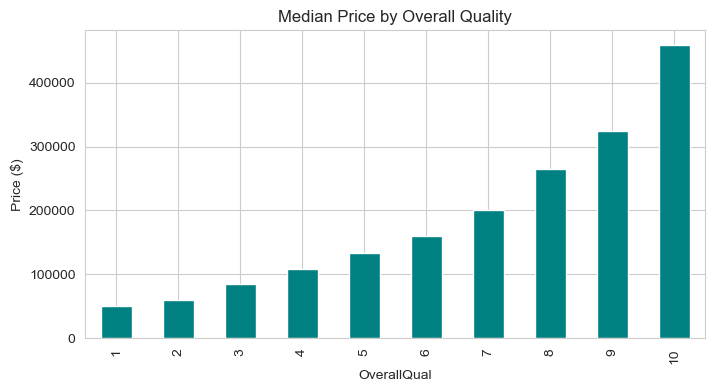

In [36]:
# Which upgrades give the most price jump per quality level?
market.groupby("OverallQual")["SalePrice"].median().plot(kind="bar", color="teal", figsize=(8, 4))
plt.title("Median Price by Overall Quality")
plt.ylabel("Price ($)")
plt.show()

**Task 3 conclusion:** each house is compared with its out-of-fold predicted (fair) price. A positive `ValueScore%` means the asking price is below the fair value. Recommendations are limited to normal sales and filtered by the buyer's budget, area, bedrooms, bathrooms, quality, garage, age and neighborhood. Neighborhood price per sq ft and the quality-vs-price chart help buyers decide where and how much quality to pay for.

# Model Comparison Report

## 1. Goal
Predict house prices in Ames, Iowa and choose the best model for production.

## 2. How the models were tested
- 80% of the data for training, 20% for testing
- Price was converted to log(price) so the models work better
- 5-fold cross-validation (CV) on the training data, then a final test on the unseen 20%
- Lower RMSE and MAE are better, and higher R² is better

## 3. Results

| Rank | Model | CV RMSE (log) | Test R² | Test MAE ($) |
|---|---|---|---|---|
| 1 | XGBoost | 0.1125 | 0.9232 | 13,211 |
| 2 | ElasticNet | 0.1129 | 0.9190 | 14,046 |
| 3 | Ridge | 0.1132 | 0.9105 | 14,436 |
| 4 | Gradient Boosting | 0.1133 | 0.9198 | 13,689 |
| 5 | Lasso | 0.1139 | 0.9176 | 13,916 |
| 6 | Random Forest | 0.1321 | 0.8836 | 15,877 |
| 7 | Linear Regression | 1.07 x 10^10 | -4.17 x 10^17 | 3,337,050 |

**Linear Regression failed.** It gave absurd predictions because many features are correlated and there are 200+ one-hot columns. It is left out of the comparison.

## 4. Key points
- The top 5 models are very close (CV RMSE 0.1125 to 0.1139).
- **XGBoost is the best**: lowest error and highest R² (0.9232).
- Ridge, Lasso and ElasticNet are almost as good (R² 0.91 to 0.92) and much simpler.
- Random Forest is the weakest working model.
- CV and test errors are close for all models, so there is no serious overfitting.

## 5. Tuning (Gradient Boosting)
- Tried 15 settings with 5-fold CV. Best: `n_estimators=500`, `learning_rate=0.05`, `max_depth=2`, `subsample=0.8`, `min_samples_leaf=5`
- CV RMSE: 0.1133 before tuning, 0.1178 after
- Tuning gave no clear improvement, because the default settings were already strong.

## 6. Final tuned Gradient Boosting (test set)

| R² | RMSE ($) | MAE ($) | MAPE |
|---|---|---|---|
| 0.9226 | 19,533 | 14,162 | 8.45% |

On average, a prediction is off by about $14,000 (about 8.5% of the price).

## 7. Recommendation
**Use the XGBoost pipeline in production.**
- Best accuracy and a very small gap between CV and test error
- Handles non-linear patterns in the data
- The pipeline includes preprocessing, so raw data can be passed in directly

**Simpler option:** ElasticNet. It is almost as accurate, faster, and easy to explain.

*Note:* the tuned Gradient Boosting model (R² 0.9226) was used for the feature analysis and buyer recommendations.

## 8. Limitations
- Data is from one city (Ames), 2006 to 2010, so retrain for other markets or years.
- Retrain regularly as prices change.

## Challenges & Techniques

| Challenge | What I did | Why |
|---|---|---|
| Many missing values (79 features) | Filled with "None" or 0 when the feature does not exist; used the neighborhood median for LotFrontage | In this data, a missing value usually means "the house has no such feature" |
| Skewed price (SalePrice) | Used log(price) | Makes the data more balanced and the models more stable |
| Two outliers (GrLivArea > 4000, low price) | Removed them | They are partial sales and distort the model |
| Text and number columns mixed | ColumnTransformer + OneHotEncoder in a Pipeline | Models need numbers, and a pipeline avoids data leakage |
| Quality ratings (Po, Fa, TA, Gd, Ex) | Converted to numbers 0 to 5 | Keeps the order of the ratings |
| Correlated features (for example GarageCars and GarageArea) | Used Ridge, Lasso and tree models; added TotalSF | Regularization handles correlated features |
| Risk of overfitting | 5-fold cross-validation, regularization, tuning | Gives honest performance results |
| Raw features carry limited information | Created new features (TotalSF, HouseAge, TotalBath, flags) | Combined features carry more price information |
| Codes that are really categories (MSSubClass, MoSold) | Converted to text | Avoids a false number order |
| Linear Regression gave absurd predictions | Used Ridge, Lasso, ElasticNet and tree models instead | Many correlated and one-hot columns make plain Linear Regression unstable |
| Some houses looked like bargains but were not | Recommended only normal sales (`SaleCondition == "Normal"`) | Partial and abnormal sales are priced by special deals, not the market |